# Final results figure panels

This notebook uses the exported `ground_truth.csv` and `model.csv` files. It creates separate Familiar and Novel B panels, the sector grouped C panel, and an Appendix C version with three additional model ablation columns. The existing vector and cosine plotting functions are used unchanged for D and E.

Trace ribbons show ±1 sample SD by default: across neurons for data and across seeds for model, after averaging repeated images within each replicate. D ellipses show ±1 SD across neuron/seed transition vectors. E point plot error bars show ±1 SD across empirical neuron-level cosine values. The transition proportions are descriptive sample fractions, shown with their percentages.

In [1]:
from pathlib import Path
import sys
from IPython.display import Image, display

cwd = Path.cwd().resolve()
PAPER_DIR = cwd / "paper_v2" if (cwd / "paper_v2" / "plot.py").exists() else cwd
REPO_DIR = PAPER_DIR.parent
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from paper_v2 import plot

plot.use_myriad_pro()
import pandas as pd
DATA = pd.read_csv(PAPER_DIR / "ground_truth.csv")
MODEL = pd.read_csv(PAPER_DIR / "model.csv")
PLOTTED_DATA = DATA.loc[~DATA.sector.eq("-O axis")]
OUT = PAPER_DIR / "figures" / "final_layout"
OUT.mkdir(parents=True, exist_ok=True)
FONT_SIZE = 12
UNCERTAINTY = "sem"

## Panel B — Familiar

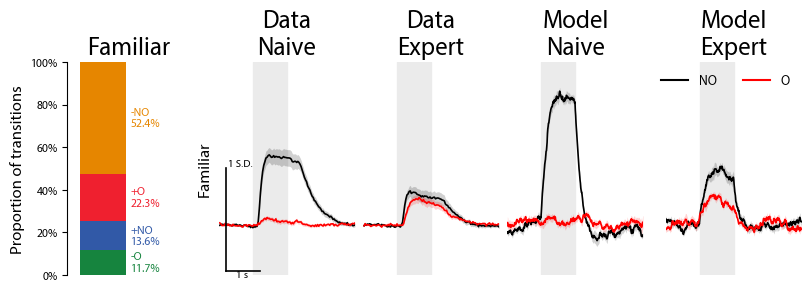

In [2]:
fig, axes = plot.panel_b(DATA, MODEL, source="familiar", width=8, height=2.8,
                            fontsize=FONT_SIZE, uncertainty=UNCERTAINTY)
display(fig)
plot.save(fig, OUT / "panel_B_familiar")

### Familiar transition proportions (standalone export)

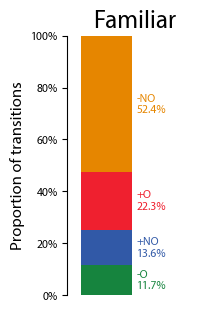

In [3]:
fig, ax = plot.panel_b_proportions(DATA, source="familiar", width=2, height=3,
                                       fontsize=FONT_SIZE)
display(fig)
plot.save(fig, OUT / "panel_B_familiar_proportions")

## Panel B — Novel

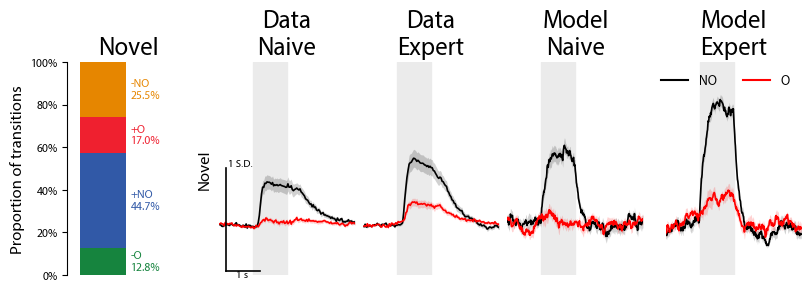

In [4]:
fig, axes = plot.panel_b(DATA, MODEL, source="novel", width=8, height=2.8,
                            fontsize=FONT_SIZE, uncertainty=UNCERTAINTY)
display(fig)
plot.save(fig, OUT / "panel_B_novel")

### Novel transition proportions (standalone export)

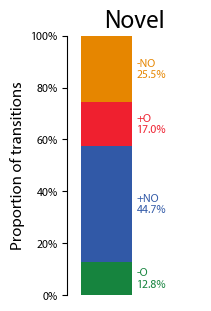

In [5]:
fig, ax = plot.panel_b_proportions(DATA, source="novel", width=2, height=3,
                                       fontsize=FONT_SIZE)
display(fig)
plot.save(fig, OUT / "panel_B_novel_proportions")

## Panel C — sector grouped traces

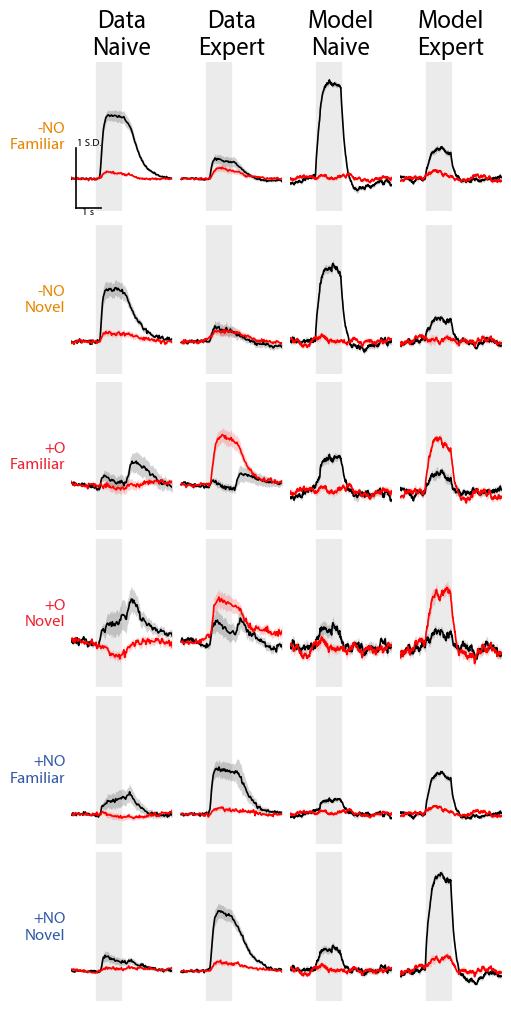

In [6]:
fig, axes = plot.panel_c(DATA, MODEL, width=5, height=10, fontsize=FONT_SIZE,
                            uncertainty=UNCERTAINTY)
display(fig)
plot.save(fig, OUT / "panel_C")

## Appendix C — Panel C plus three model ablation columns

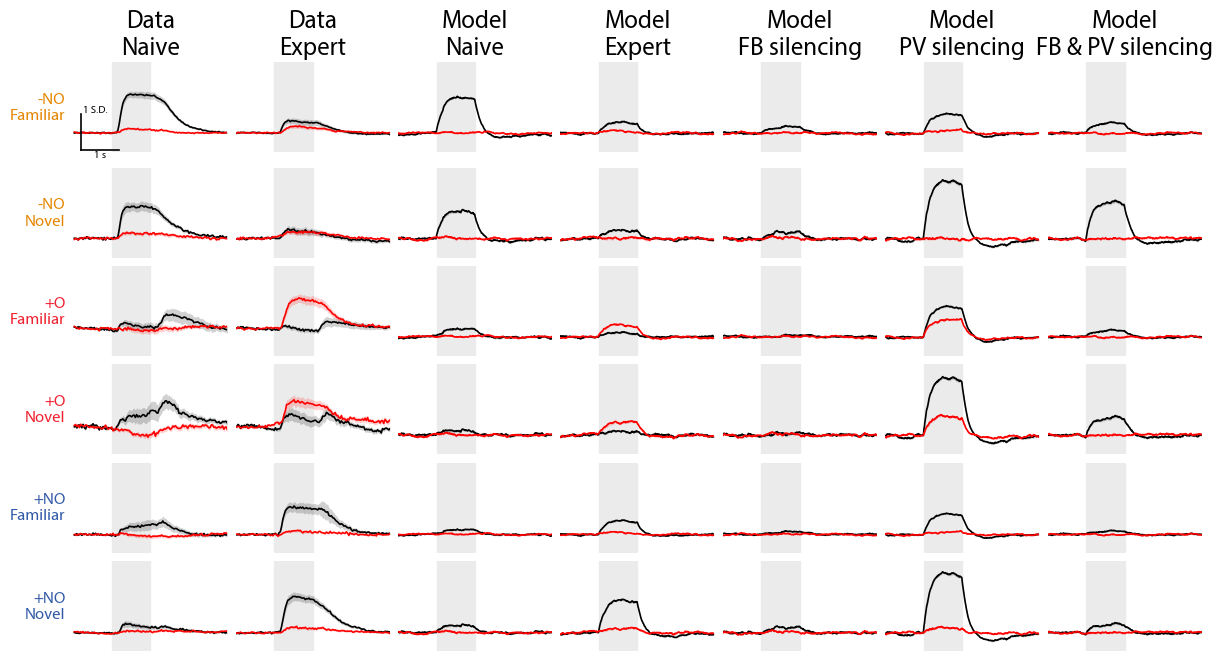

In [7]:
fig, axes = plot.panel_c_appendix(DATA, MODEL, width=12, height=6.5, fontsize=FONT_SIZE,
                                     uncertainty=UNCERTAINTY)
display(fig)
plot.save(fig, OUT / "appendix_C")

## Panel D — existing transition vector plots

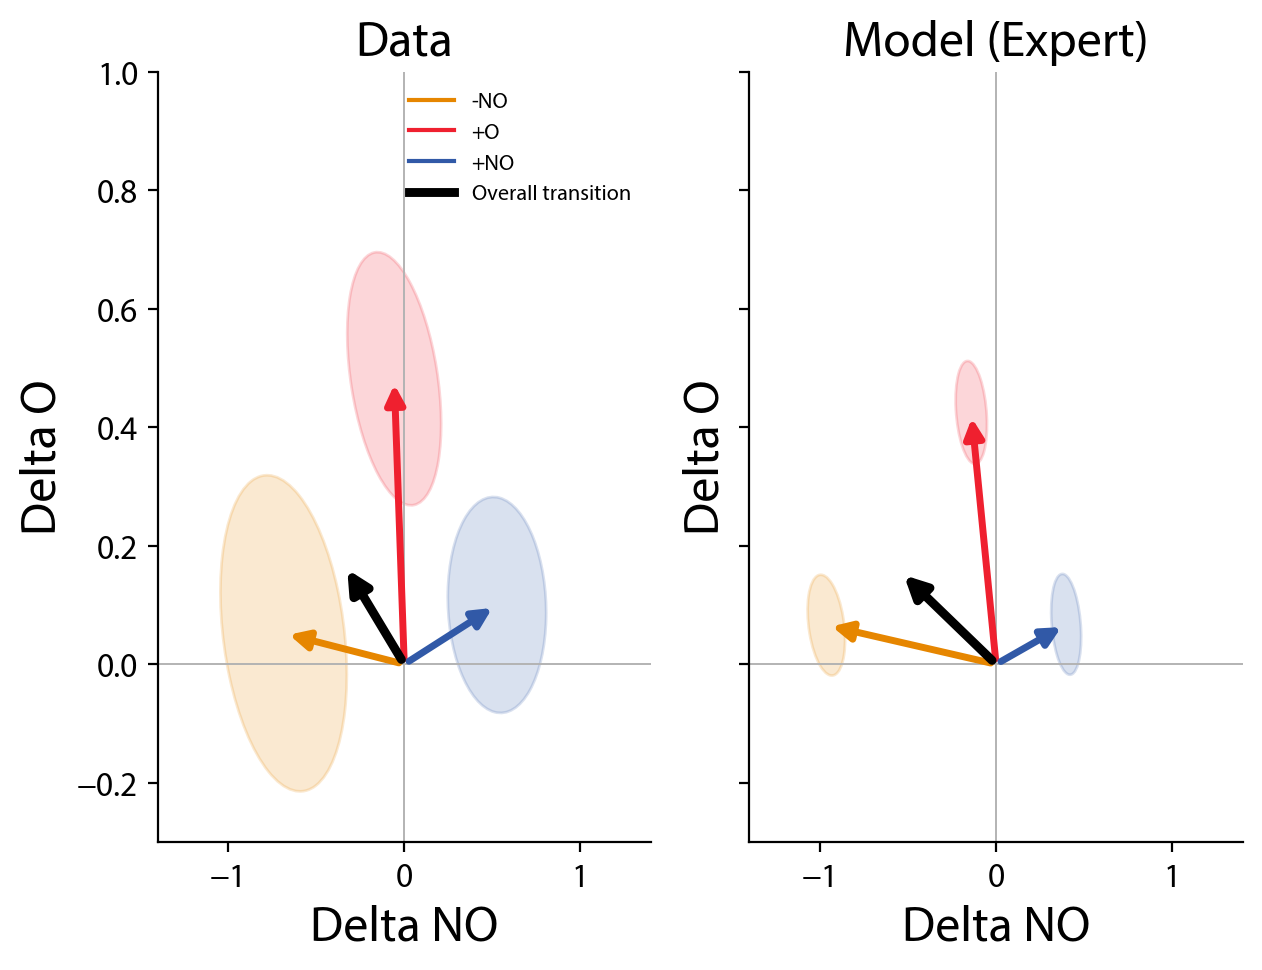

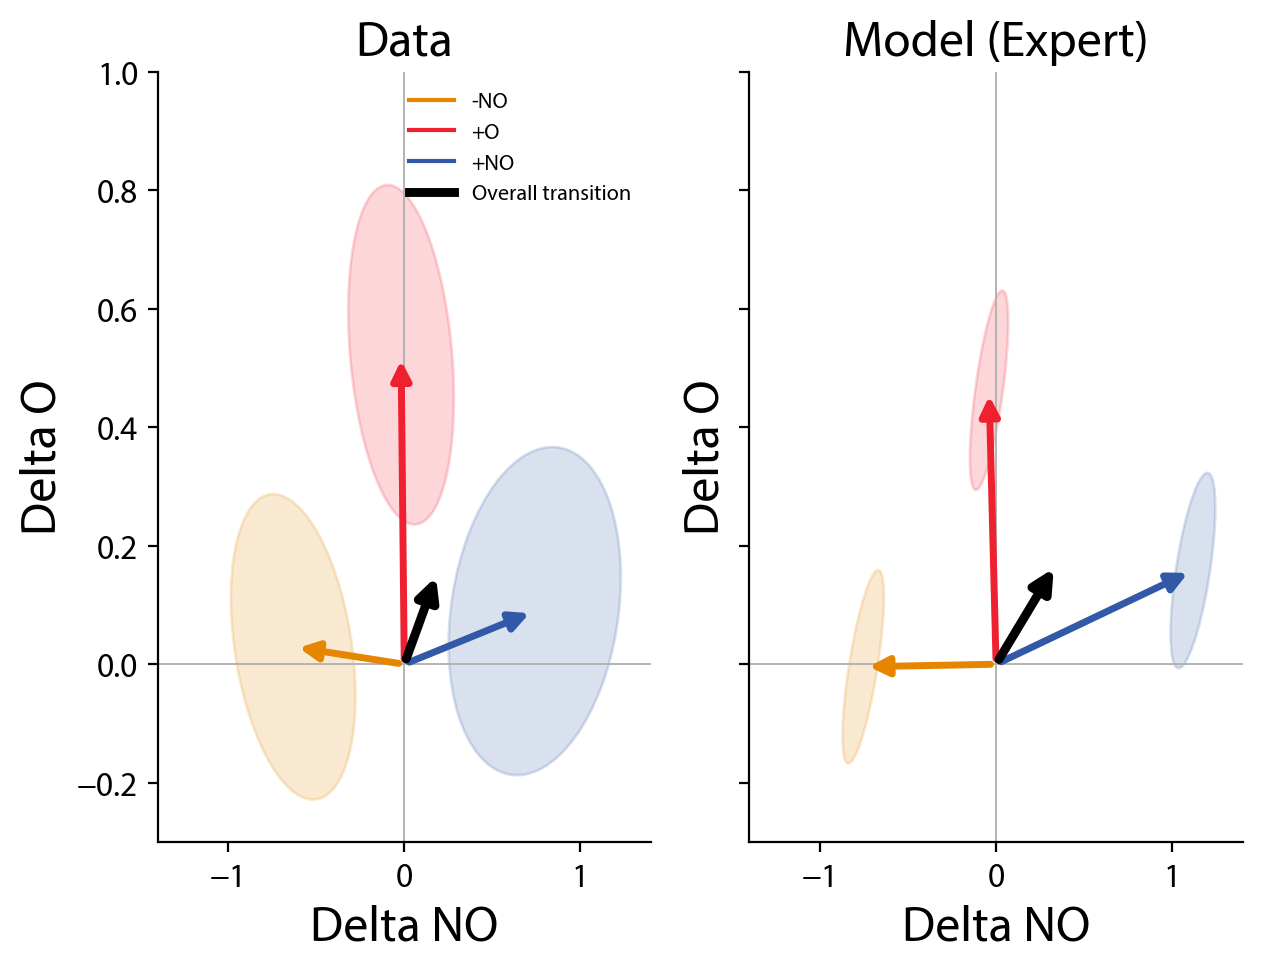

In [8]:
plot.plot_vectors(PLOTTED_DATA, MODEL, "familiar", OUT / "panel_D_familiar",
                  uncertainty='sd', condition="expert")
plot.plot_vectors(PLOTTED_DATA, MODEL, "novel", OUT / "panel_D_novel",
                  uncertainty='sd', condition="expert")
display(Image(filename=OUT / "panel_D_familiar.png"))
display(Image(filename=OUT / "panel_D_novel.png"))

## Panel E — existing cosine similarity plots

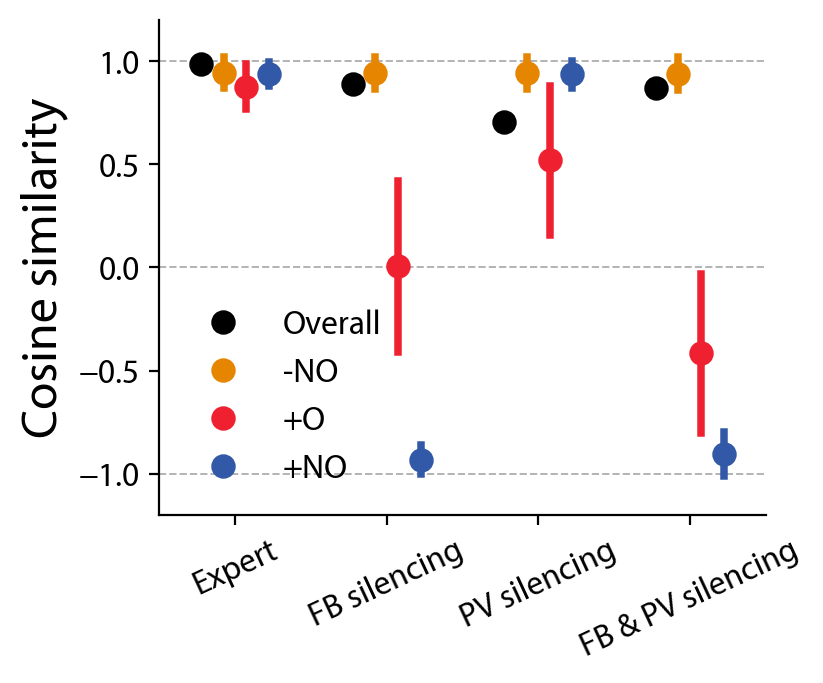

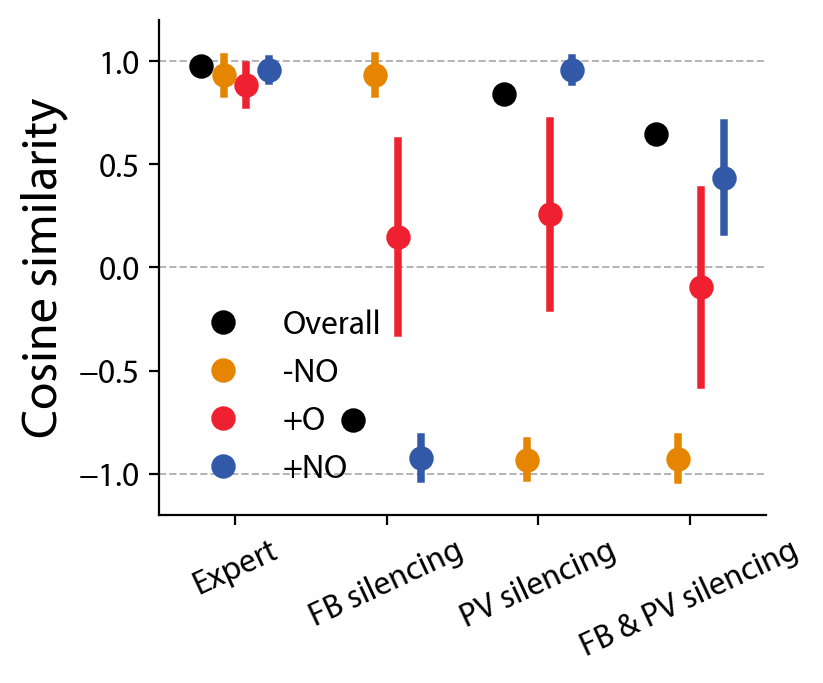

In [9]:
plot.plot_similarities(PLOTTED_DATA, MODEL, "familiar", OUT / "panel_E_familiar_cosine",
                       errorbars=True, #uncertainty=('se', 2)
                       )
plot.plot_similarities(PLOTTED_DATA, MODEL, "novel", OUT / "panel_E_novel_cosine",
                       errorbars=True, #uncertainty=('se', 2)
                       )
display(Image(filename=OUT / "panel_E_familiar_cosine.png"))
display(Image(filename=OUT / "panel_E_novel_cosine.png"))

The panel B/C plotting functions accept dimensions in inches and a font size. Existing D and E plotting functions retain their prior plot sizes, axes, and calculations. All files are saved as PNG and SVG under `figures/final_layout/`.